# LandscapeSHAP demo: RBF-kernel SVM, approximate (Monte Carlo) point-level Shapley values

This notebook mirrors `linear-exact-landscapeshap.ipynb` -- same dynamical-system dataset,
same persistence-landscape featurization -- but trains a **nonlinear RBF-kernel SVM**
instead of a linear one. A nonlinear kernel means the point-level Shapley game no longer has
a closed form (Theorem 1 only covers models linear in the landscape features), so Section 5
below approximates it with **Monte Carlo permutation sampling** instead: the K-buffer
estimator from the write-up's Algorithm 2, with one extra trick -- all `N+1` prefix
landscapes generated while walking through a single permutation are stacked into one batch
and scored with a **single** `model.decision_function` call, since that call is already
vectorized over samples. That cuts the number of expensive kernel evaluations from `O(N)`
calls per permutation down to `O(1)`.

This notebook:

1. Samples point clouds from the same coupled logistic-type torus map, for the same 5 values
   of `r` (identical `RNG_SEED`, identical sampling code -- the two notebooks' datasets agree
   point-for-point).
2. Computes degree-1 persistent homology (H1) with the alpha complex (GUDHI) -- identical to
   the linear notebook.
3. Builds the same fixed-length persistence-landscape features.
4. Trains an **RBF-kernel multiclass SVM** (`sklearn.svm.SVC`) to predict `r`.
5. **Approximates** point-level Shapley values for every point in a persistence diagram via
   Monte Carlo permutation sampling (no closed form exists for this model), and sanity-checks
   the estimator against brute-force exact Shapley values on a small synthetic diagram scored
   by the *same* fitted model.
6. Produces the same two figure types as the linear notebook: (a) a quick sanity-check plot
   of the 5 example point clouds, and (b) for each example, the H1 diagram colored by
   (approximate) Shapley value, plus the alpha-complex triangulation and newly-born H1 cycle
   at each of the top-5 |Shapley|-value points' birth times.

**Design choices made where the request was ambiguous** (documented again at the end): the
RBF SVM uses `C=10.0, gamma="scale"` without a hyperparameter search, to keep runtime
predictable -- tune these if accuracy matters more than notebook speed. The number of MC
permutations `T` per example diagram is a runtime/precision trade-off, set conservatively
below; increase it if the *individual* point-level attributions look noisy across reruns
(the printed `sum(phi)` vs. `Delta` check matches to numerical precision at any `T`, by a
telescoping-sum property of permutation sampling -- see Section 5 -- so it does not indicate
precision at the individual-point level).


In [1]:
!pip install -q gudhi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 35.6 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import gudhi
from collections import deque, defaultdict
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)


## 1. Dynamical system: sample the point clouds

$$x_{n+1} = x_n + r\cdot y_n(1-y_n) \bmod 1, \qquad y_{n+1} = y_n + r\cdot x_{n+1}(1-x_{n+1}) \bmod 1$$

Identical sampling code and `RNG_SEED` to `linear-exact-landscapeshap.ipynb`, so the two
notebooks' point clouds agree exactly.


In [3]:
def sample_orbit(r, n_points=1000, burn_in=500, rng=None):
    """Iterate the coupled torus map and return n_points samples on the attractor."""
    rng = rng or np.random.default_rng()
    x, y = rng.uniform(), rng.uniform()
    for _ in range(burn_in):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
    pts = np.empty((n_points, 2))
    for i in range(n_points):
        x = (x + r * y * (1.0 - y)) % 1.0
        y = (y + r * x * (1.0 - x)) % 1.0
        pts[i, 0] = x
        pts[i, 1] = y
    return pts

R_VALUES = [2.0, 3.5, 4.0, 4.1, 4.3]
N_CLOUDS_PER_R = 100
N_POINTS = 1000

point_clouds, labels = [], []
for r in R_VALUES:
    for _ in range(N_CLOUDS_PER_R):
        point_clouds.append(sample_orbit(r, n_points=N_POINTS, burn_in=500, rng=rng))
        labels.append(r)
labels = np.array(labels)
print(f"Generated {len(point_clouds)} point clouds, {N_POINTS} points each.")

EXAMPLE_INDICES = [int(np.where(labels == r)[0][0]) for r in R_VALUES]


Generated 500 point clouds, 1000 points each.


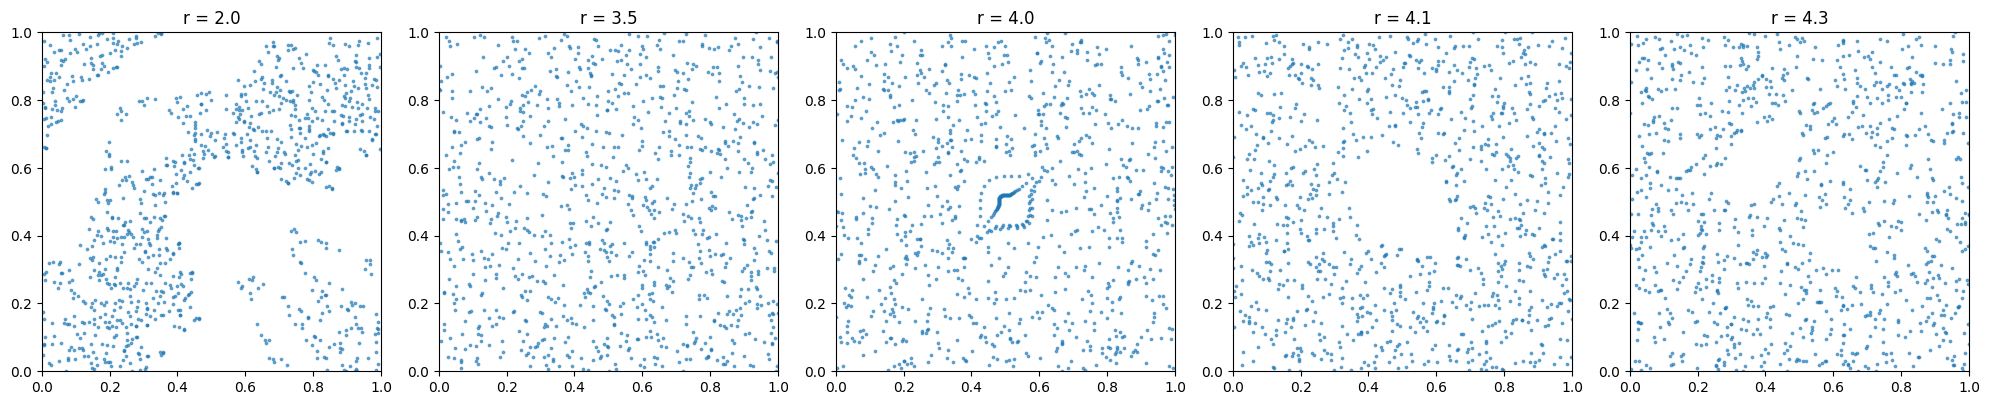

In [4]:
fig, axes = plt.subplots(1, len(R_VALUES), figsize=(4 * len(R_VALUES), 4))
for ax, idx in zip(axes, EXAMPLE_INDICES):
    ax.scatter(point_clouds[idx][:, 0], point_clouds[idx][:, 1], s=3, alpha=0.6)
    ax.set_title(f"r = {labels[idx]}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
plt.tight_layout()
fig.savefig("rbf_dynamics_examples.svg", format="svg", bbox_inches="tight")
plt.show()


## 2. Persistent homology (H1, alpha complex)

Identical to the linear notebook: GUDHI `AlphaComplex`, square-rooted filtration values,
birth-edge / death-triangle kept for every H1 pair, noise threshold and grid picked from the
data.


In [5]:
def compute_h1(points):
    """H1 persistence pairs for a 2D point cloud via the alpha complex.
    Returns a list of (birth, death, birth_simplex, death_simplex) tuples;
    birth_simplex/death_simplex are lists of vertex indices into `points`."""
    ac = gudhi.AlphaComplex(points=points)
    st = ac.create_simplex_tree()
    st.persistence(homology_coeff_field=2, min_persistence=0)
    h1 = []
    for birth_s, death_s in st.persistence_pairs():
        if len(birth_s) == 2 and len(death_s) == 3:
            b = np.sqrt(max(st.filtration(birth_s), 0.0))
            d = np.sqrt(max(st.filtration(death_s), 0.0))
            h1.append((b, d, birth_s, death_s))
    return h1

raw_h1 = [compute_h1(pc) for pc in point_clouds]

NOISE_FRAC = 0.02
all_deaths = np.concatenate([[p[1] for p in h1] for h1 in raw_h1 if h1])
GRID_MAX = float(np.percentile(all_deaths, 99) * 1.1)
EPSILON = NOISE_FRAC * GRID_MAX
M = 100
grid = np.linspace(0.0, GRID_MAX, M)
print(f"Grid max: {GRID_MAX:.4f}   noise threshold: {EPSILON:.5f}")

def filter_h1(h1):
    return [p for p in h1 if (p[1] - p[0]) > EPSILON]

h1_diagrams = [filter_h1(h1) for h1 in raw_h1]
print("Median / min / max surviving H1 features per cloud:",
      np.median([len(h) for h in h1_diagrams]),
      np.min([len(h) for h in h1_diagrams]),
      np.max([len(h) for h in h1_diagrams]))


Grid max: 0.0541   noise threshold: 0.00108
Median / min / max surviving H1 features per cloud: 320.0 1 376


## 3. Featurization: persistence landscapes

Identical to the linear notebook: `K = 25` layers, zero-padded when a diagram has fewer than
`K` surviving H1 features.


In [6]:
K = 15  # number of landscape layers

def landscape(h1, grid, K):
    N = len(h1)
    M = len(grid)
    if N == 0:
        return np.zeros((K, M))
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                       np.maximum(0.0, d[:, None] - grid[None, :]))  # (N, M)
    sorted_tent = np.sort(tent, axis=0)[::-1]
    L = np.zeros((K, M))
    L[:min(K, N)] = sorted_tent[:min(K, N)]
    return L

landscapes = [landscape(h1, grid, K).flatten() for h1 in h1_diagrams]
X = np.array(landscapes)  # (n_samples, K*M)
print("Feature matrix:", X.shape)


Feature matrix: (500, 1500)


## 4. Train a nonlinear (RBF-kernel) multiclass SVM

Same `%g`-string label trick as the linear notebook (`r_to_label`), needed for the same
reason: `r` is a float array with only 5 distinct values, but scikit-learn's target-type
check still calls that "continuous" unless it's handed strings/ints.

`decision_function_shape="ovr"` gives one real-valued score per class, so `decision_function`
returns shape `(n_samples, n_classes)` -- exactly the per-class score Section 5 needs to
define its coalition game (same role `model.coef_ @ x` played for the linear model, just
without a closed form now).


In [7]:
def r_to_label(r):
    return f"{r:g}"

y = np.array([r_to_label(r) for r in labels])

X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, np.arange(len(y)), test_size=0.25, stratify=y, random_state=RNG_SEED)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

model = SVC(kernel="rbf", C=10.0, gamma="scale", decision_function_shape="ovr")
model.fit(X_train_s, y_train)
print("Test accuracy:", model.score(X_test_s, y_test))
print("Classes:", model.classes_)
print("Support vectors per class:", model.n_support_)


Test accuracy: 0.856
Classes: ['2' '3.5' '4' '4.1' '4.3']
Support vectors per class: [33 35 64 56 45]


## 5. Approximate point-level Shapley values (Monte Carlo)

The RBF kernel makes the decision function a sum of nonlinear kernel evaluations against
support vectors -- it is not linear (or even additive) in the raw landscape cells, so
Theorem 1's closed form does not apply. We fall back to permutation sampling, using the same
K-buffer trick as the write-up's Algorithm 2 (maintaining a running sorted top-`K` buffer per
grid column instead of re-sorting the whole growing coalition), plus one extra trick specific
to having a real batch-capable model: instead of calling `model.decision_function` once per
step of a permutation (`O(N)` expensive kernel evaluations per permutation), we build all
`N+1` prefix landscapes for one permutation first (cheap numpy buffer operations only), stack
them into one `(N+1, K*M)` matrix, and score them with a **single** vectorized
`decision_function` call. Marginal contributions are then just consecutive differences of
that one score vector.

We first sanity-check the estimator against brute-force exact Shapley values (full
permutation enumeration) on a small synthetic diagram, scored by this notebook's actual
fitted `model`/`scaler` -- so this validates both the estimator's logic and its use of the
real model.


In [8]:
def build_prefix_landscapes(h1, grid, K, perm):
    """K-buffer landscape state after each prefix of `perm`. Returns an array of shape
    (N+1, K, M): index 0 is the empty coalition (all-zero landscape), index t is the
    landscape built from the first t points of `perm`."""
    N = len(h1)
    M = len(grid)
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent_mat = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                           np.maximum(0.0, d[:, None] - grid[None, :]))  # (N, M)
    stack = np.zeros((N + 1, K, M))
    buf = np.zeros((0, M))
    for step, idx in enumerate(perm, start=1):
        cand = np.vstack([buf, tent_mat[idx:idx + 1, :]])
        cand_sorted = -np.sort(-cand, axis=0)
        buf = cand_sorted[:K, :]
        stack[step, :buf.shape[0], :] = buf
    return stack

def mc_shapley_rbf(h1, grid, K, model, scaler, class_label, T, rng):
    """Monte Carlo point-level Shapley values for ANY model (here: an RBF SVM's
    decision_function), using the K-buffer trick and batching all N+1 prefix states of one
    permutation into a single vectorized model call."""
    N = len(h1)
    if N == 0:
        return np.zeros(0)
    c = list(model.classes_).index(class_label)
    phi_accum = np.zeros(N)
    for _ in range(T):
        perm = rng.permutation(N)
        stack = build_prefix_landscapes(h1, grid, K, perm)
        X_steps_s = scaler.transform(stack.reshape(N + 1, K * grid.shape[0]))
        scores = model.decision_function(X_steps_s)
        if scores.ndim == 1:
            scores = scores[:, None]
        v = scores[:, c]
        marg = v[1:] - v[:-1]
        phi_accum[perm] += marg
    return phi_accum / T


In [9]:
# Self-check: brute-force exact Shapley (full permutation enumeration) vs. this Monte Carlo
# estimator, both scored by the SAME fitted model. K (=25) exceeds the tiny diagram's size
# below, so the buffer never truncates and the MC estimator's only source of error is the
# usual Monte Carlo sampling noise -- it should shrink as T grows.
import itertools

def exact_shapley_bruteforce(h1, grid, K, model, scaler, class_label):
    N = len(h1)
    c = list(model.classes_).index(class_label)
    b = np.array([p[0] for p in h1])
    d = np.array([p[1] for p in h1])
    tent_mat = np.minimum(np.maximum(0.0, grid[None, :] - b[:, None]),
                           np.maximum(0.0, d[:, None] - grid[None, :]))
    M_ = len(grid)

    def v(idx_tuple):
        L = np.zeros((K, M_))
        if idx_tuple:
            sub = tent_mat[list(idx_tuple), :]
            sub_sorted = -np.sort(-sub, axis=0)
            n_fill = min(K, len(idx_tuple))
            L[:n_fill] = sub_sorted[:n_fill]
        Xs = scaler.transform(L.reshape(1, -1))
        return model.decision_function(Xs)[0, c]

    phi = np.zeros(N)
    perms = list(itertools.permutations(range(N)))
    for perm in perms:
        coalition, v_prev = [], v(())
        for p in perm:
            coalition.append(p)
            v_cur = v(tuple(coalition))
            phi[p] += v_cur - v_prev
            v_prev = v_cur
    return phi / len(perms)

check_rng = np.random.default_rng(123)
N_CHECK = 6
births_check = np.sort(check_rng.uniform(0, GRID_MAX * 0.5, size=N_CHECK))
mini_h1 = [(float(b0), float(b0 + 0.02 + 0.03 * check_rng.random())) for b0 in births_check]
check_class = r_to_label(R_VALUES[0])

phi_exact = exact_shapley_bruteforce(mini_h1, grid, K, model, scaler, check_class)
phi_mc = mc_shapley_rbf(mini_h1, grid, K, model, scaler, check_class, T=4000,
                         rng=np.random.default_rng(7))

print("Brute-force (exact) phi:  ", np.round(phi_exact, 5))
print("Monte Carlo  (T=4000) phi:", np.round(phi_mc, 5))
print("Max abs diff:", np.max(np.abs(phi_exact - phi_mc)))
print("(Small but nonzero -- this is ordinary MC sampling noise, not a bug; it shrinks as "
      "T grows.)")


Brute-force (exact) phi:   [0.09649 0.23187 0.21992 0.27258 0.14098 0.03908]
Monte Carlo  (T=4000) phi: [0.05328 0.28019 0.21601 0.27888 0.13353 0.03904]
Max abs diff: 0.04831868272399742
(Small but nonzero -- this is ordinary MC sampling noise, not a bug; it shrinks as T grows.)


## 6. Plot 5 example diagrams colored by (approximate) Shapley value, and show the
triangulation + newly-born cycle at each top-5 point's birth time

Same 5 point clouds as Section 1 (`EXAMPLE_INDICES`) and the same plot layout as the linear
notebook. The only change is where `phi` comes from: `mc_shapley_rbf` with `T_MAIN`
permutations per diagram, instead of the closed form. We also print the true `v(full) -
v(empty)` gap (`Delta`, computed exactly from the real model -- no sampling) next to
`sum(phi)`, which will match to numerical precision even at small `T_MAIN` -- for any single
permutation, the marginal contributions collected while walking through it telescope exactly
to `v(full) - v(empty)`, so this holds sample-by-sample, not just on average. That makes this
check a useful bug-catcher (a broken estimator would fail it even at `T_MAIN=1`), but it is
*not* evidence that the individual per-point `phi` values have converged -- unlike their sum,
each one still has genuine Monte Carlo variance that only shrinks as `T_MAIN` grows.


In [10]:
def compute_edges(points):
    """All 1-simplices (edges) of the alpha complex, with filtration values (sqrt'd to
    match the birth/death scale used elsewhere)."""
    ac = gudhi.AlphaComplex(points=points)
    st = ac.create_simplex_tree()
    return [(s[0], s[1], np.sqrt(max(f, 0.0))) for s, f in st.get_skeleton(1) if len(s) == 2]

def representative_cycle(edges, u, v, birth_time, eps=1e-9):
    """BFS shortest path from u to v using only edges strictly earlier than birth_time."""
    adj = defaultdict(list)
    for i, j, f in edges:
        if f < birth_time - eps:
            adj[i].append(j)
            adj[j].append(i)
    if u == v:
        return [u]
    visited = {u: None}
    queue = deque([u])
    while queue:
        cur = queue.popleft()
        if cur == v:
            break
        for nxt in adj[cur]:
            if nxt not in visited:
                visited[nxt] = cur
                queue.append(nxt)
    if v not in visited:
        return [u, v]
    path = [v]
    while path[-1] != u:
        path.append(visited[path[-1]])
    path.reverse()
    return path


r= 2.0: sum(phi)= 1.041146   Delta= 1.041146   |diff|=0.0000   predicted=2
r= 3.5: sum(phi)= 4.543932   Delta= 4.543932   |diff|=0.0000   predicted=3.5
r= 4.0: sum(phi)= 3.471777   Delta= 3.471777   |diff|=0.0000   predicted=4
r= 4.1: sum(phi)= 0.059887   Delta= 0.059887   |diff|=0.0000   predicted=4.1
r= 4.3: sum(phi)= 2.214262   Delta= 2.214262   |diff|=0.0000   predicted=4.3


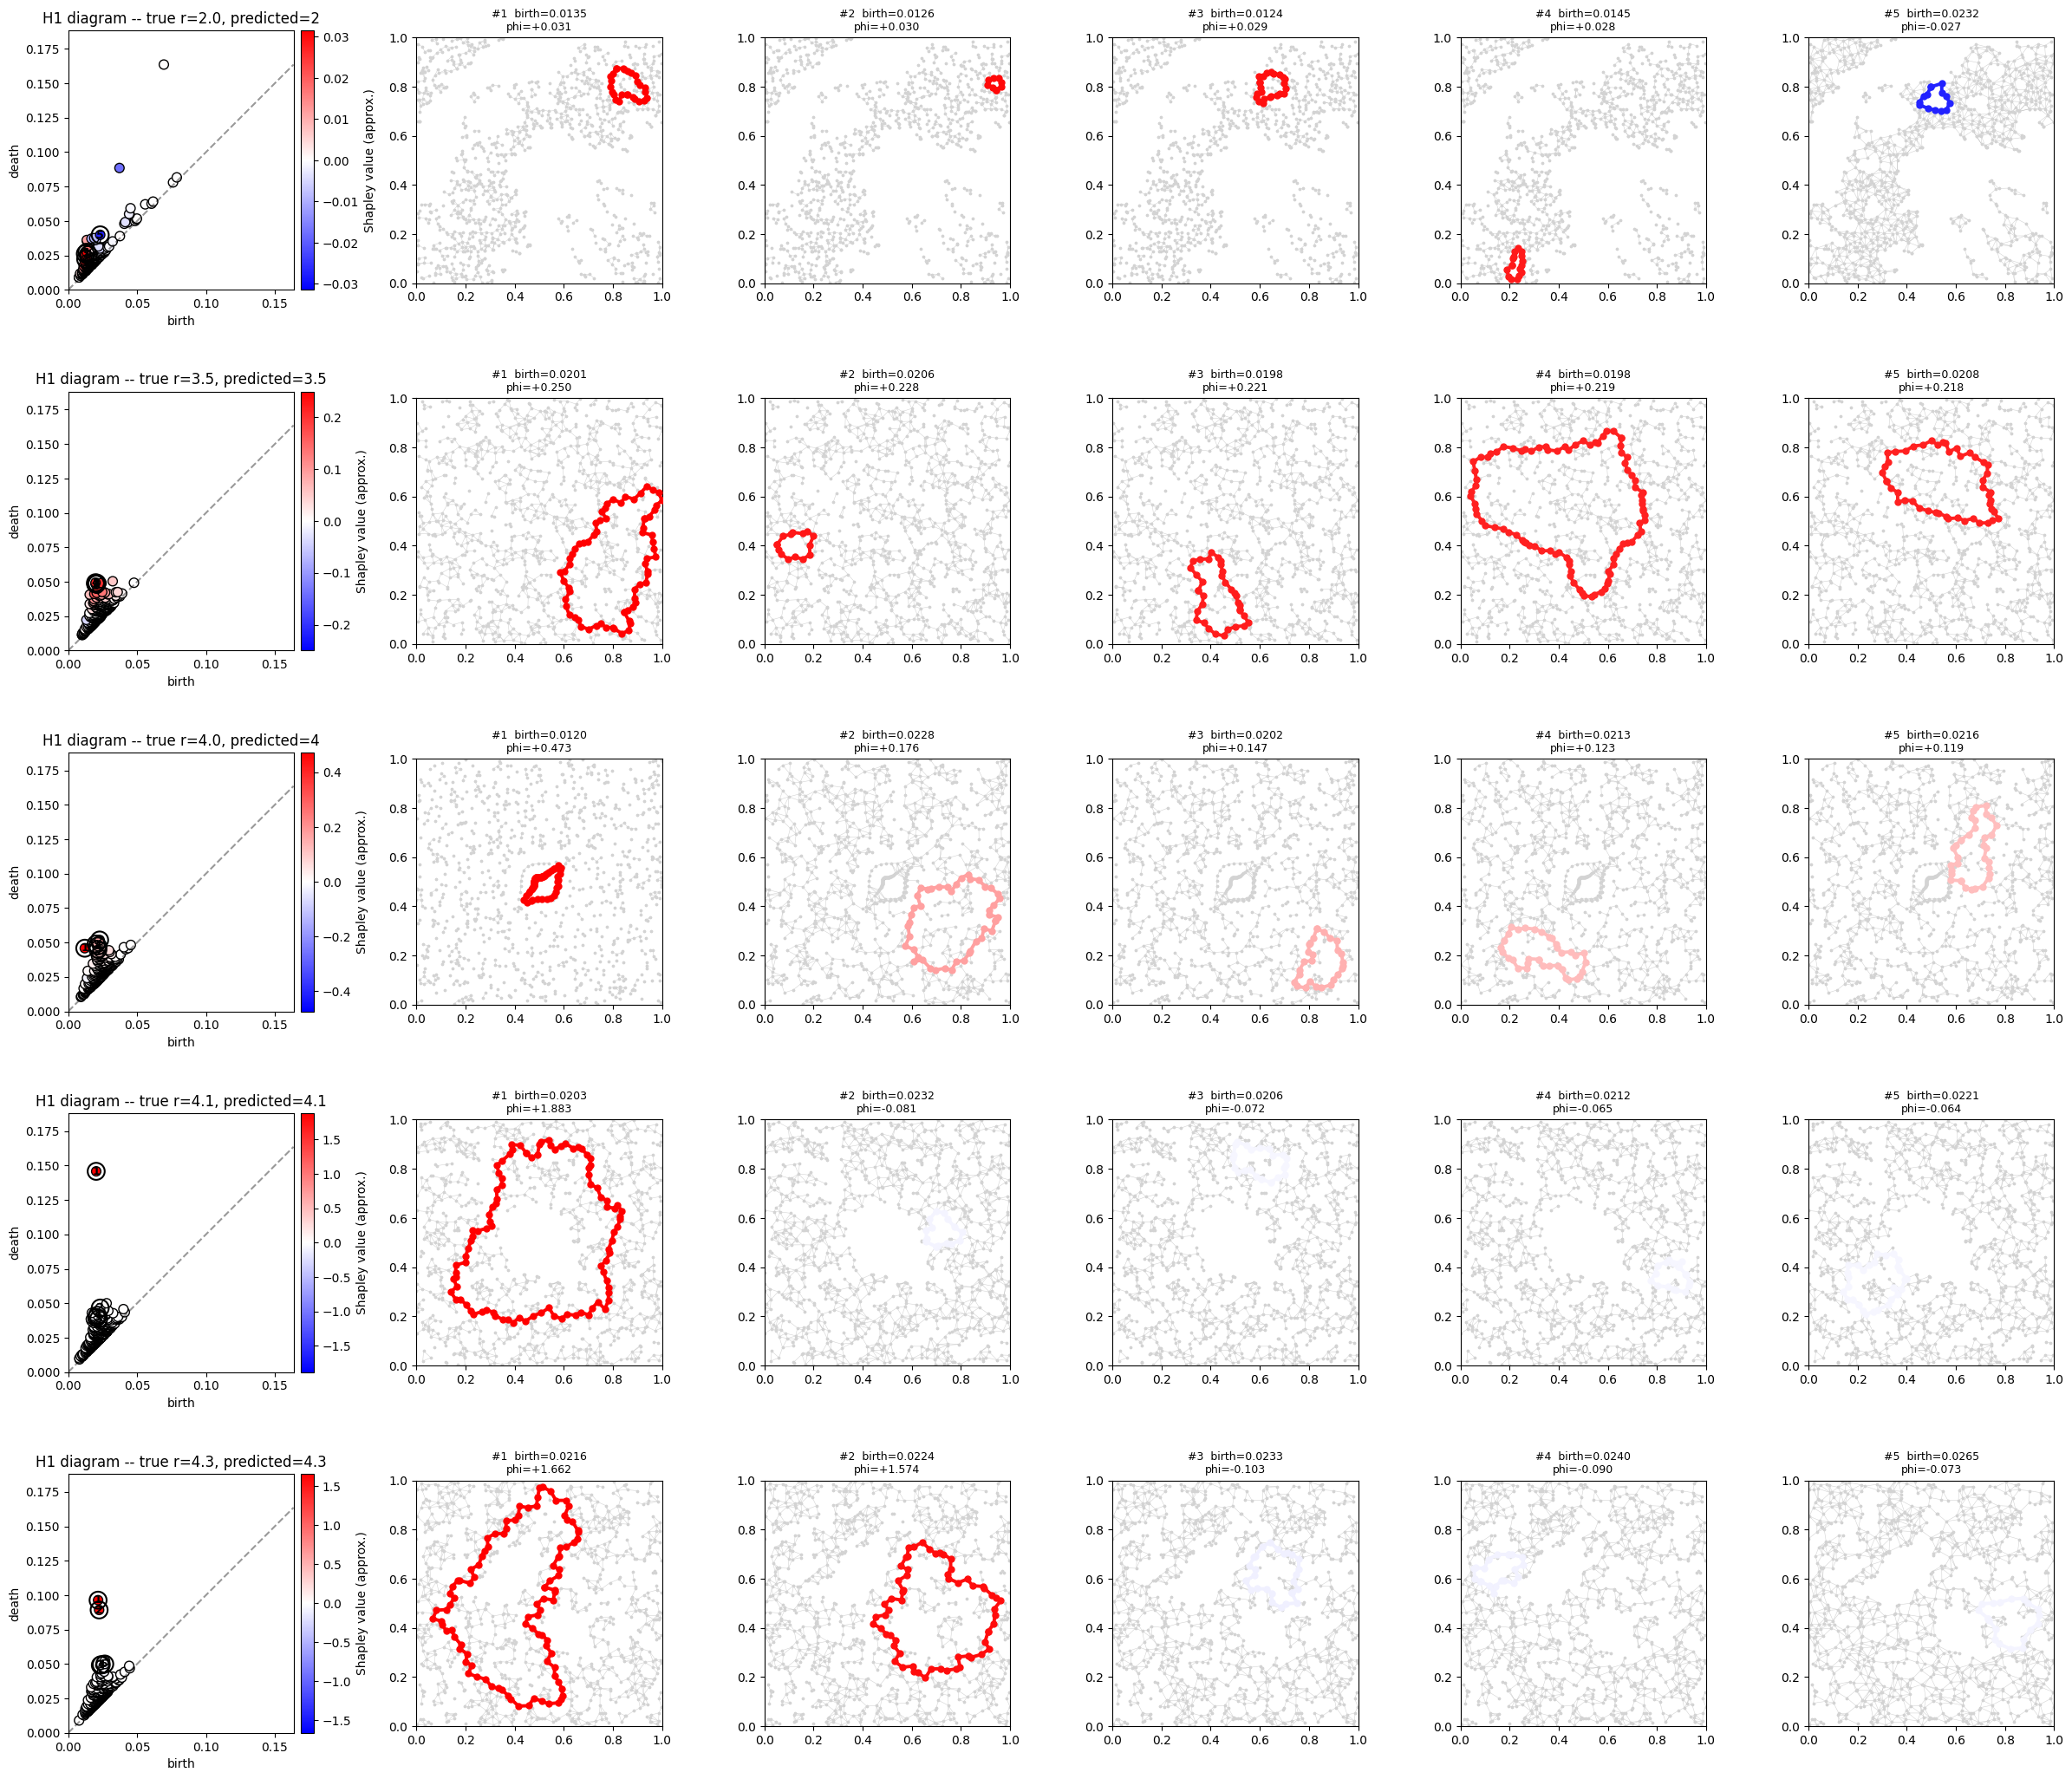

In [11]:
T_MAIN = 3000  # MC permutations per example diagram -- raise for a tighter efficiency
              # check, lower for a faster run

example_indices = [idx for idx in EXAMPLE_INDICES if len(h1_diagrams[idx]) > 0]
if len(example_indices) < len(EXAMPLE_INDICES):
    print(f"Note: {len(EXAMPLE_INDICES) - len(example_indices)} example cloud(s) had no "
          "surviving H1 features and were skipped.")

N_TOP = 5
cmap = plt.cm.bwr
fig, axes = plt.subplots(len(example_indices), 1 + N_TOP,
                          figsize=(4 * (1 + N_TOP), 4.2 * len(example_indices)))

# The largest death coordinate actually appearing among the diagrams we're about to plot --
# NOT GRID_MAX, which is a 99th-percentile cutoff over the whole dataset used to size the
# landscape feature grid and is deliberately allowed to sit below individual diagrams' true
# max (that's what makes it a noise-trimmed grid rather than a display range). Using GRID_MAX
# here would silently crop real points off the visible frame.
PLOT_MAX = max(max(p[1] for p in h1_diagrams[idx]) for idx in example_indices)

for row, idx in enumerate(example_indices):
    h1 = h1_diagrams[idx]
    true_r = labels[idx]
    class_label = r_to_label(true_r)
    c = list(model.classes_).index(class_label)

    phi = mc_shapley_rbf(h1, grid, K, model, scaler, class_label, T=T_MAIN, rng=rng)

    v_empty = model.decision_function(scaler.transform(np.zeros((1, K * M))))[0, c]
    v_full = model.decision_function(scaler.transform(X[idx:idx + 1]))[0, c]
    delta = float(v_full - v_empty)
    pred = model.predict(scaler.transform(X[idx:idx + 1]))[0]
    print(f"r={true_r:>4}: sum(phi)={phi.sum(): .6f}   Delta={delta: .6f}   "
          f"|diff|={abs(phi.sum() - delta):.4f}   predicted={pred}")

    b_arr = np.array([p[0] for p in h1])
    d_arr = np.array([p[1] for p in h1])
    vmax = max(np.max(np.abs(phi)), 1e-8)
    norm = plt.Normalize(vmin=-vmax, vmax=vmax)

    ax = axes[row, 0]
    sc = ax.scatter(b_arr, d_arr, c=phi, cmap=cmap, norm=norm, s=60, edgecolors="k")
    ax.plot([0, PLOT_MAX], [0, PLOT_MAX], "k--", alpha=0.4)
    ax.set_title(f"H1 diagram -- true r={true_r}, predicted={pred}")
    ax.set_xlabel("birth"); ax.set_ylabel("death")
    # Same birth/death scale on every row's diagram (shared PLOT_MAX, the true max death
    # coordinate among the plotted diagrams), so the 5 examples are visually comparable rather
    # than each auto-scaling to its own point range, and no real point ends up cropped off. A
    # bit of headroom above PLOT_MAX on the death axis only, so the top-most points and the
    # birth==death diagonal aren't crowded against the frame.
    ax.set_xlim(0, PLOT_MAX)
    ax.set_ylim(0, PLOT_MAX * 1.15)
    ax.set_aspect("equal")
    # Attach the colorbar as a same-height axes carved out of ax itself (rather than
    # plt.colorbar's default, which sizes off the *pre-aspect-lock* bounding box -- with
    # set_aspect("equal") the diagram axes end up shorter than that box once rendered, so the
    # default colorbar comes out taller than the diagram and spills into neighboring text).
    cax = make_axes_locatable(ax).append_axes("right", size="6%", pad=0.08)
    plt.colorbar(sc, cax=cax, label="Shapley value (approx.)")

    n_top_here = min(N_TOP, len(phi))
    top_idx = np.argsort(-np.abs(phi))[:n_top_here]
    ax.scatter(b_arr[top_idx], d_arr[top_idx], facecolors="none", edgecolors="k",
               s=200, linewidths=1.5)
    for rank, j in enumerate(top_idx):
        ax.annotate(str(rank + 1), (b_arr[j], d_arr[j]), fontsize=9, weight="bold",
                     ha="center", va="center")

    pc = point_clouds[idx]
    edges = compute_edges(pc)

    for col in range(N_TOP):
        ax2 = axes[row, 1 + col]
        if col >= n_top_here:
            ax2.axis("off")
            continue
        j = top_idx[col]
        birth_time, death_time, birth_s, death_s = h1[j]
        color = cmap(norm(phi[j]))

        for i0, i1, f in edges:
            if f <= birth_time + 1e-9:
                p0, p1 = pc[i0], pc[i1]
                ax2.plot([p0[0], p1[0]], [p0[1], p1[1]], color="gray",
                          linewidth=0.4, alpha=0.35, zorder=1)
        ax2.scatter(pc[:, 0], pc[:, 1], s=3, color="lightgray", zorder=2)

        u, v = birth_s
        path = representative_cycle(edges, u, v, birth_time)
        loop = path + [path[0]]
        loop_xy = pc[loop]
        ax2.plot(loop_xy[:, 0], loop_xy[:, 1], "-", color=color, linewidth=2.8, zorder=5)
        ax2.scatter(loop_xy[:, 0], loop_xy[:, 1], color=color, s=25, zorder=6)

        ax2.set_xlim(0, 1); ax2.set_ylim(0, 1)
        ax2.set_aspect("equal")
        ax2.set_title(f"#{col + 1}  birth={birth_time:.4f}\nphi={phi[j]:+.3f}", fontsize=9)

plt.tight_layout()
fig.savefig("rbf_shap_representative_cycles.svg", format="svg", bbox_inches="tight")
plt.show()


## Notes on design choices / caveats

- **Model hyperparameters.** `C=10.0, gamma="scale"` are fixed defaults, not cross-validated
  -- if test accuracy looks weak for your run, a small grid search over `C`/`gamma` is a
  drop-in change to Section 4.
- **Why Monte Carlo, not closed form.** Theorem 1 in the write-up gives an exact, sort-only
  formula for models linear in the landscape cells. An RBF SVM's decision function is a sum
  of Gaussian kernel evaluations against support vectors -- nonlinear and non-additive in the
  raw features -- so no such shortcut applies; Section 5 approximates instead, per the
  write-up's Section 8 ("Beyond linear models") discussion.
- **Two independent speedups, stacked.** The K-buffer trick avoids re-sorting the whole
  growing coalition at every step (`O(K log K)` instead of `O(s log s)` per step). Separately,
  batching all `N+1` prefix landscapes of one permutation into a single `decision_function`
  call avoids `O(N)` separate (relatively expensive, kernel-evaluating) model calls per
  permutation, replacing them with 1. The two are independent: the K-buffer trick bounds the
  cost of *building* each landscape; the batching trick bounds the number of *model
  evaluations*.
- **`T_MAIN` is a runtime/precision knob, but the `sum(phi)` vs. `Delta` line doesn't measure
  it.** That check matches to numerical precision at any `T_MAIN`, including `T_MAIN=1` --
  permutation sampling satisfies the efficiency axiom exactly, sample-by-sample, not just in
  expectation (Section 5). It's a useful check that the estimator isn't broken, but it says
  nothing about whether individual `phi_i` values have converged; those still have real Monte
  Carlo variance. Raise `T_MAIN` if per-point attributions look unstable across reruns; lower
  it if the notebook is running too slowly on your diagrams' sizes.
- **Which class is explained; example clouds aren't guaranteed held-out.** Same as the linear
  notebook: each example explains the model's score for the true `r`, and `EXAMPLE_INDICES`
  is fixed before the train/test split exists.
- **Representative cycle.** Same BFS-based (fewest-hops, not minimal-weight) construction as
  the linear notebook; see its notes for the same caveat.
